# E2 — Diagnóstico do colapso da validação nos métodos MT

Nas runs do E2, os métodos com teacher EMA têm `val/dice_patient` ≈ 0,85 até o passo ~4500 e depois **caem a ~0**.
Supervisionado e FixMatch ficam estáveis. O best-ckpt (passos 2000–3000) esconde isso nas tabelas.

**Hipóteses**

| | hipótese | assinatura esperada |
|---|---|---|
| H1 | overfitting / consistência estraga os pesos do student | `dice_student_eval` também colapsa; colapso acompanha λ (D2 mais cedo, D3 pior, D1 sem colapso) |
| H2 | artefato do teacher em eval mode (pesos EMA + BN copiado do student) | `dice_student_eval` e `dice_teacher_bnrecal` ficam bons; só `dice_teacher_eval` cai; D1 (λ=0) também colapsa |
| H3 | solução degenerada da consistência (tudo fundo) | `fg_frac_*` → 0 também no student e nos não rotulados |

**Runs** (`scripts/e2_diag.py`, DeepLabV3+, seed 42, 8000 passos, sem split de teste):

| id | mudança |
|---|---|
| D0 | nenhuma (reproduz o colapso com a sonda) |
| D1 | λ = 0 (supervisionado + teacher EMA) |
| D2 | ramp-up em 50% do orçamento |
| D3 | λ = 1,0 |
| D4 | lr ~constante |
| D5 | `student_augment: weak` |
| D6 | weak + λ = 0,03 + `ema_decay` 0,999 |
| D7 | supervisionado + weak (controle) |

Lançar: `scripts/submit.sh` não se aplica (não é um sweep); use `tmux new -s e2diag "python scripts/e2_diag.py run"`.

In [1]:
import sys
sys.path.append("../../../")

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path("../../../").resolve()
DIAG_RUNS = ROOT / "logs" / "e2-diag" / "runs"
E2_RUNS = ROOT / "logs" / "_arquivo" / "e2-sem-aug" / "runs"   # E2 sem augmentation (referência)
RUN_UID = "s42"           # "s42-smoke" para conferir o smoke test

# Referências já rodadas no E2 (sem sonda): supervisionado e MT originais.
REFERENCES = {
    "E2-sup": E2_RUNS / "e2-deeplabv3plus-supervised-global-s42",
    "E2-mt": E2_RUNS / "e2-deeplabv3plus-meanteacher-global-s42",
}

In [3]:
def latest_metrics(run_dir: Path) -> pd.DataFrame:
    """metrics.csv do run (o mais recente se houver vários timestamps)."""
    candidates = sorted(run_dir.glob("*/csv/metrics.csv")) or sorted(run_dir.glob("csv/metrics.csv"))
    if not candidates:
        raise FileNotFoundError(run_dir)
    return pd.read_csv(candidates[-1])


def val_table(df: pd.DataFrame) -> pd.DataFrame:
    """Uma linha por validação: todas as colunas val*/probe/*, indexadas pelo passo."""
    cols = [c for c in df.columns if c.startswith(("val/", "val_student/", "probe/"))]
    out = df.loc[df[cols].notna().any(axis=1), ["step"] + cols].groupby("step").last()
    return out


def train_table(df: pd.DataFrame, every: int = 500) -> pd.DataFrame:
    """Médias de treino por janela de `every` passos, alinhadas ao passo da validação."""
    t = df[df["train/sup_loss"].notna()].copy()
    t["bin"] = (t["step"] // every) * every + every - 1
    cols = [c for c in ["train/dice_score", "train/sup_loss", "train/unsup_loss",
                        "train/consistency_weight"] if c in t]
    return t.groupby("bin")[cols].mean()


runs = {}
for run_dir in sorted(DIAG_RUNS.glob("e2diag-*")):
    uid_dir = run_dir / RUN_UID
    if uid_dir.exists():
        key = run_dir.name.split("-")[1]                  # D0, D1, ...
        runs[key] = {"name": run_dir.name, "df": pd.read_csv(uid_dir / "csv" / "metrics.csv")}
for key, path in REFERENCES.items():
    if path.exists():
        runs[key] = {"name": path.name, "df": latest_metrics(path)}

tables = {k: val_table(r["df"]).join(train_table(r["df"]), how="left") for k, r in runs.items()}
print({k: r["name"] for k, r in runs.items()})

{'D0': 'e2diag-D0-mt-probe', 'D1': 'e2diag-D1-mt-lambda0', 'D2': 'e2diag-D2-mt-ramp-half', 'D3': 'e2diag-D3-mt-lambda1', 'D4': 'e2diag-D4-mt-constlr', 'D5': 'e2diag-D5-mt-aug', 'D6': 'e2diag-D6-mt-aug-reg', 'D7': 'e2diag-D7-sup-aug', 'E2-sup': 'e2-deeplabv3plus-supervised-global-s42', 'E2-mt': 'e2-deeplabv3plus-meanteacher-global-s42'}


## 1. Teacher vs student vs teacher com BN recalibrado

A leitura central: se `student_eval` e `teacher_bnrecal` seguem bons enquanto `teacher_eval` colapsa → **H2**.

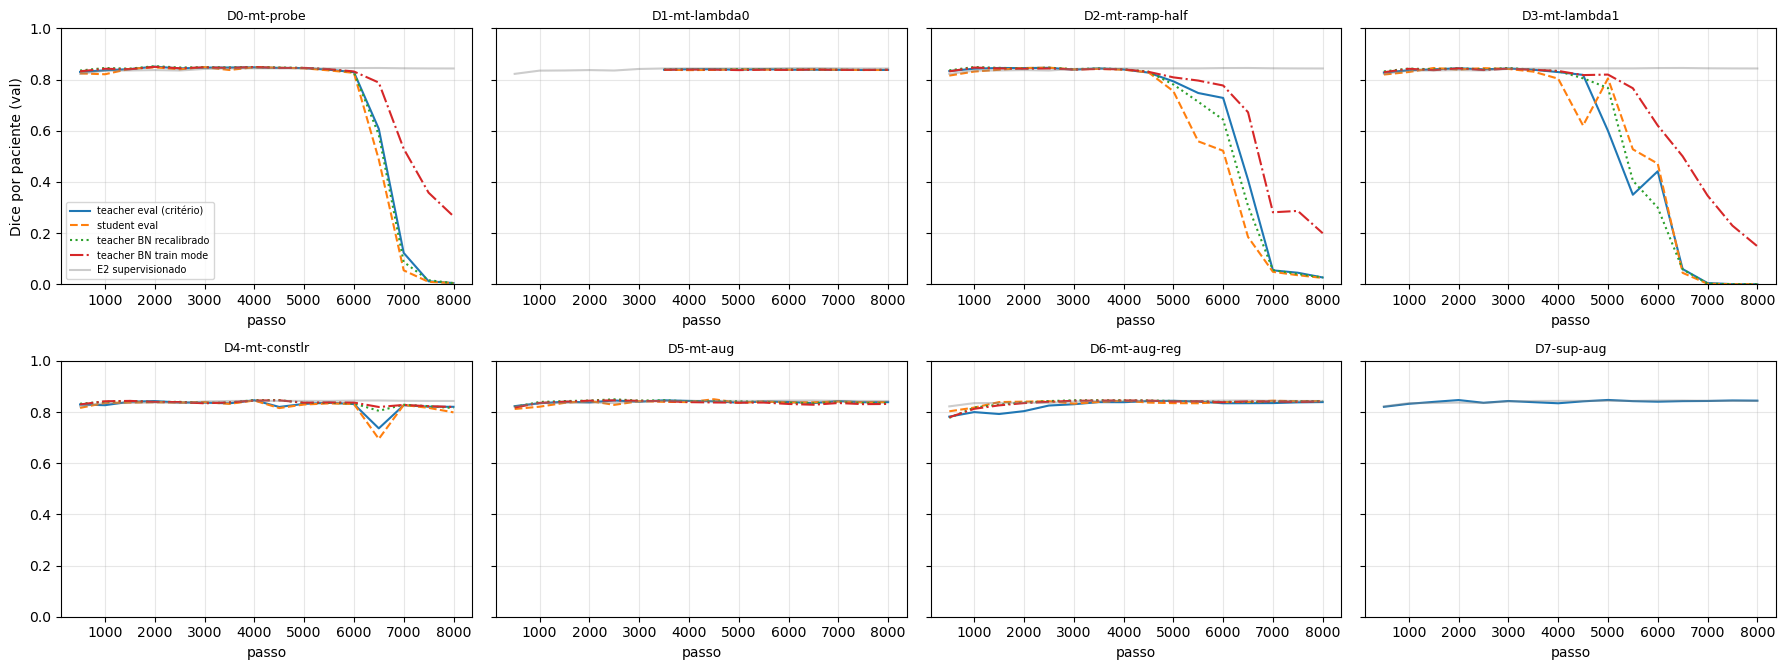

In [10]:
CURVES = {
    "val/dice_patient": ("teacher eval (critério)", "-"),
    "val_student/dice_patient": ("student eval", "--"),
    "probe/dice_teacher_bnrecal": ("teacher BN recalibrado", ":"),
    "probe/dice_teacher_trainbn": ("teacher BN train mode", "-."),
}
keys = [k for k in tables if k.startswith("D")]
n = len(keys)
fig, axes = plt.subplots(int(np.ceil(n / 4)) or 1, min(n, 4) or 1, figsize=(4.5 * min(n, 4), 3.4 * int(np.ceil(n / 4))),
                         squeeze=False, sharey=True)
for ax, key in zip(axes.flat, keys):
    t = tables[key]
    for col, (label, style) in CURVES.items():
        if col in t:
            ax.plot(t.index, t[col], style, label=label)
    if "E2-sup" in tables:
        ax.plot(tables["E2-sup"].index, tables["E2-sup"]["val/dice_patient"], color="grey", alpha=.4, label="E2 supervisionado")
    ax.set_title(runs[key]["name"].replace("e2diag-", ""), fontsize=9)
    ax.set_ylim(0, 1); ax.set_xlabel("passo"); ax.grid(alpha=.3)
axes.flat[0].set_ylabel("Dice por paciente (val)")
axes.flat[0].legend(fontsize=7)
for ax in list(axes.flat)[n:]:
    ax.axis("off")
plt.tight_layout()

## 2. Colapso para "tudo fundo"? (H3)

`fg_frac_*` = fração de pixels previstos como FG. Compare com `fg_frac_gt` (val). `fg_frac_unl_*` é medido nos não rotulados recentes do treino.

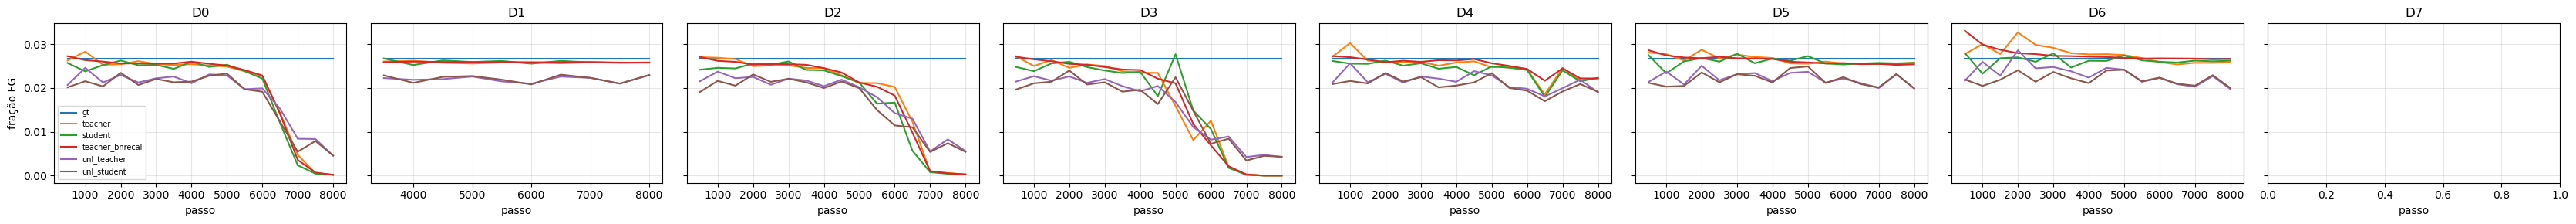

In [11]:
FG = ["probe/fg_frac_gt", "probe/fg_frac_teacher", "probe/fg_frac_student", "probe/fg_frac_teacher_bnrecal",
      "probe/fg_frac_unl_teacher", "probe/fg_frac_unl_student"]
fig, axes = plt.subplots(1, len(keys) or 1, figsize=(4.2 * max(len(keys), 1), 3), squeeze=False, sharey=True)
for ax, key in zip(axes.flat, keys):
    t = tables[key]
    for col in FG:
        if col in t:
            ax.plot(t.index, t[col], label=col.replace("probe/fg_frac_", ""))
    ax.set_title(key); ax.grid(alpha=.3); ax.set_xlabel("passo")
axes.flat[0].set_ylabel("fração FG"); axes.flat[0].legend(fontsize=7)
plt.tight_layout()

## 3. Overfitting (H1): gap treino–val medido no mesmo modo (eval)

`probe/train_dice_eval_student` é o Dice por frame num subconjunto **fixo** de frames rotulados de treino, em eval mode.
O `train/dice_score` de sempre é medido em train mode (BN do lote) e por isso não é comparável com a val.

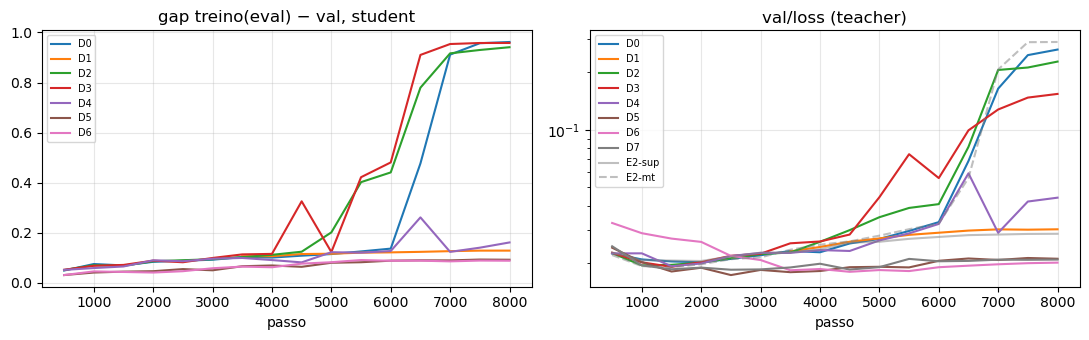

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for key in keys:
    t = tables[key]
    if "probe/train_dice_eval_student" in t and "val_student/dice_patient" in t:
        gap = t["probe/train_dice_eval_student"] - t["val_student/dice_patient"]
        axes[0].plot(t.index, gap, label=key)
    if "val/loss" in t:
        axes[1].plot(t.index, t["val/loss"], label=key)
for ref in ("E2-sup", "E2-mt"):
    if ref in tables:
        axes[1].plot(tables[ref].index, tables[ref]["val/loss"], color="grey", ls="--" if ref == "E2-mt" else "-", alpha=.5, label=ref)
axes[0].set_title("gap treino(eval) − val, student"); axes[1].set_title("val/loss (teacher)")
axes[1].set_yscale("log")
for ax in axes:
    ax.grid(alpha=.3); ax.set_xlabel("passo"); ax.legend(fontsize=7)
plt.tight_layout()

## 4. Teacher vs student: distância de pesos e saúde do BN

running_var não finitos (máximo ao longo da run): {'D0': {'probe/bn_nonfinite_student': 0.0, 'probe/bn_nonfinite_teacher': 0.0}, 'D1': {'probe/bn_nonfinite_student': 0.0, 'probe/bn_nonfinite_teacher': 0.0}, 'D2': {'probe/bn_nonfinite_student': 0.0, 'probe/bn_nonfinite_teacher': 0.0}, 'D3': {'probe/bn_nonfinite_student': 0.0, 'probe/bn_nonfinite_teacher': 0.0}, 'D4': {'probe/bn_nonfinite_student': 0.0, 'probe/bn_nonfinite_teacher': 0.0}, 'D5': {'probe/bn_nonfinite_student': 0.0, 'probe/bn_nonfinite_teacher': 0.0}, 'D6': {'probe/bn_nonfinite_student': 0.0, 'probe/bn_nonfinite_teacher': 0.0}, 'D7': {}}


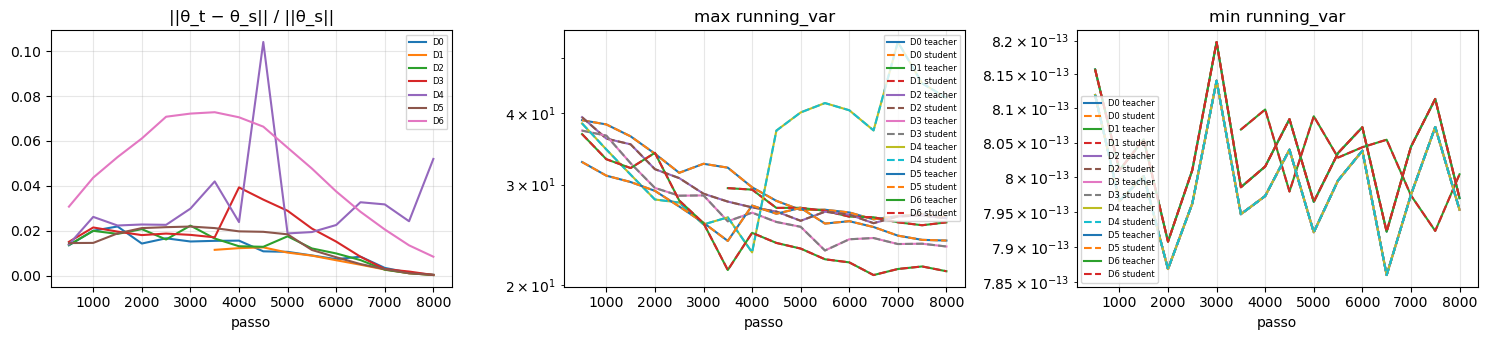

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for key in keys:
    t = tables[key]
    if "probe/param_dist" in t:
        axes[0].plot(t.index, t["probe/param_dist"], label=key)
    for who, ls in (("teacher", "-"), ("student", "--")):
        if f"probe/bn_var_max_{who}" in t:
            axes[1].plot(t.index, t[f"probe/bn_var_max_{who}"], ls, label=f"{key} {who}")
        if f"probe/bn_var_min_{who}" in t:
            axes[2].plot(t.index, t[f"probe/bn_var_min_{who}"], ls, label=f"{key} {who}")
axes[0].set_title("||θ_t − θ_s|| / ||θ_s||"); axes[1].set_title("max running_var"); axes[2].set_title("min running_var")
for ax in axes[1:]:
    ax.set_yscale("log")
for ax in axes:
    ax.grid(alpha=.3); ax.set_xlabel("passo"); ax.legend(fontsize=6)
plt.tight_layout()
nonfinite = {k: tables[k].filter(like="bn_nonfinite").max().to_dict() for k in keys}
print("running_var não finitos (máximo ao longo da run):", nonfinite)

## 5. Augmentation resolve? (D5–D7 contra D0 e o supervisionado)

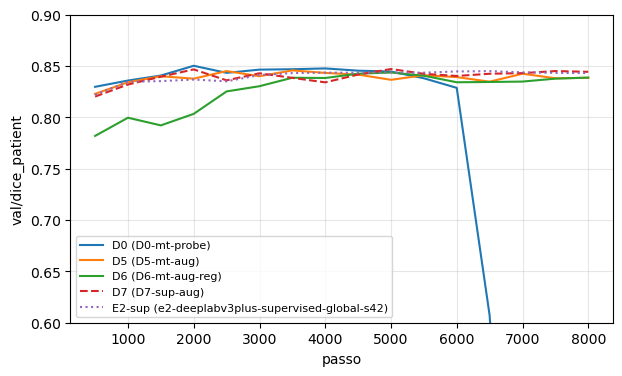

In [16]:
fig, ax = plt.subplots(figsize=(7, 4))
for key, style in (("D0", "-"), ("D5", "-"), ("D6", "-"), ("D7", "--"), ("E2-sup", ":")):
    if key in tables:
        ax.plot(tables[key].index, tables[key]["val/dice_patient"], style, label=f"{key} ({runs[key]['name'].replace('e2diag-', '')})")
ax.set_ylim(0.6, 0.9); ax.grid(alpha=.3); ax.set_xlabel("passo"); ax.set_ylabel("val/dice_patient"); ax.legend(fontsize=8)

## 6. Resumo e tabela de decisão

Por run: pico (passo), valor no fim, e a queda pico→fim para teacher e student. "Colapsou" = valor final < 0,5.

In [17]:
def summarize(key):
    t = tables[key]
    row = {"run": runs[key]["name"]}
    for col, short in (("val/dice_patient", "teacher"), ("val_student/dice_patient", "student"),
                       ("probe/dice_teacher_bnrecal", "bnrecal")):
        if col in t and t[col].notna().any():
            s = t[col].dropna()
            row[f"{short}_pico"] = s.max(); row[f"{short}_passo_pico"] = int(s.idxmax())
            row[f"{short}_fim"] = s.iloc[-1]
    if "probe/fg_frac_student" in t:
        row["fg_student_fim"] = t["probe/fg_frac_student"].dropna().iloc[-1]
        row["fg_gt"] = t["probe/fg_frac_gt"].dropna().iloc[-1]
    return row

summary = pd.DataFrame([summarize(k) for k in tables]).set_index("run")
summary.round(3)

,teacher_pico,teacher_passo_pico,teacher_fim,student_pico,student_passo_pico,student_fim,bnrecal_pico,bnrecal_passo_pico,bnrecal_fim,fg_student_fim,fg_gt
run,,,,,,,,,,,
e2diag-D0-mt-probe,0.850,1999,0.005,0.848,2999.0,0.005,0.852,1999.0,0.004,0.000,0.027
e2diag-D1-mt-lambda0,0.840,5499,0.837,0.840,4999.0,0.837,0.841,5499.0,0.837,0.026,0.027
e2diag-D2-mt-ramp-half,0.846,2499,0.026,0.846,2499.0,0.025,0.849,999.0,0.027,0.000,0.027
e2diag-D3-mt-lambda1,0.844,1999,0.000,0.845,1499.0,0.000,0.845,2999.0,0.000,0.000,0.027
e2diag-D4-mt-constlr,0.846,3999,0.820,0.845,3999.0,0.799,0.846,3999.0,0.815,0.022,0.027
e2diag-D5-mt-aug,0.846,3499,0.839,0.850,4499.0,0.839,0.850,2499.0,0.835,0.026,0.027
e2diag-D6-mt-aug-reg,0.844,4999,0.839,0.845,3999.0,0.843,0.846,3499.0,0.843,0.026,0.027
e2diag-D7-sup-aug,0.847,4999,0.844,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
e2-deeplabv3plus-supervised-global-s42,0.845,6499,0.843,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [18]:
def verdict(summary: pd.DataFrame) -> str:
    def collapsed(run_prefix, col="teacher_fim"):
        rows = summary[summary.index.str.contains(run_prefix)]
        return None if rows.empty or col not in rows else bool(rows[col].iloc[0] < 0.5)

    lines = []
    d0_t, d0_s, d0_r = collapsed("D0"), collapsed("D0", "student_fim"), collapsed("D0", "bnrecal_fim")
    lines.append(f"D0: teacher colapsou={d0_t}, student colapsou={d0_s}, teacher+BN recalibrado colapsou={d0_r}")
    if d0_t and d0_s is False and d0_r is False:
        lines.append("→ H2: só a avaliação do teacher quebra; pesos estão bons. Correção C1 (bn_buffer_mode ema/recalibrate).")
    elif d0_t and d0_s:
        lines.append("→ pesos do student também pioram: H1 ou H3 (ver fg_frac e D1/D2/D3). Correção C2.")
    d1 = collapsed("D1")
    if d1 is not None:
        lines.append(f"D1 (λ=0) colapsou={d1} → " + ("independe da consistência (H2)." if d1 else "a consistência é necessária para o colapso."))
    for k in ("D5", "D6"):
        c = collapsed(k)
        if c is not None:
            lines.append(f"{k} colapsou={c}")
    return "\n".join(lines)

print(verdict(summary))

D0: teacher colapsou=True, student colapsou=True, teacher+BN recalibrado colapsou=True
→ pesos do student também pioram: H1 ou H3 (ver fg_frac e D1/D2/D3). Correção C2.
D1 (λ=0) colapsou=False → a consistência é necessária para o colapso.
D5 colapsou=False
D6 colapsou=False
